# 01 - Dataset exploration: MVTec AD `transistor`

This notebook summarises the dataset that was actually used. It is descriptive only: no
model is trained, no threshold is chosen, and no modelling decision is derived from the
anomalous test images. The evidence comes from the recorded audit
(`reports/metrics/<category>/dataset_audit.json`) and EDA summary (`reports/metrics/<category>/eda_summary.json`),
produced by `scripts/01_validate_dataset.py` and `scripts/02_explore_dataset.py`.

**Dataset**: official MVTec AD download, category `transistor`, license CC BY-NC-SA 4.0.
Images are not redistributed with this repository.

In [1]:
from pathlib import Path
import io
import json
import sys

import pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display

CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(path for path in CANDIDATES if (path / "configs" / "config.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from industrial_defect.config import configured_path, load_config

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)


def show(path, width=1100):
    # Display a saved figure at a bounded width so notebook outputs stay small.
    pil = PILImage.open(path)
    ratio = min(1.0, width / pil.width)
    if ratio < 1.0:
        pil = pil.resize((width, int(pil.height * ratio)), PILImage.Resampling.LANCZOS)
    buffer = io.BytesIO()
    pil.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
category = str(config["data"]["category"])
metrics_dir = configured_path(config, "metrics_dir") / category
predictions_dir = configured_path(config, "predictions_dir") / category
figures_dir = configured_path(config, "figures_dir") / category
print("project root:", PROJECT_ROOT.name)
print(f"category: {category}")

project root: transistor
category: transistor


## Split and class counts

The table is re-derived from the dataset layout, not copied from the audit.

In [2]:
from industrial_defect.config import category_dir
from industrial_defect.dataset import discover_samples

cat_dir = category_dir(config)
samples = {"train": discover_samples(cat_dir, "train"), "test": discover_samples(cat_dir, "test")}
rows = []
for split, items in samples.items():
    for defect in sorted({item.defect_type for item in items}):
        subset = [item for item in items if item.defect_type == defect]
        rows.append(
            {
                "split": split,
                "class": defect,
                "images": len(subset),
                "ground_truth_masks": sum(item.mask_path is not None for item in subset),
            }
        )
counts = pd.DataFrame(rows)
counts.loc[len(counts)] = ["all", "total", int(counts["images"].sum()), int(counts["ground_truth_masks"].sum())]
counts

,split,class,images,ground_truth_masks
0,train,good,213,0
1,test,bent_lead,10,10
2,test,cut_lead,10,10
3,test,damaged_case,10,10
4,test,good,60,0
5,test,misplaced,10,10
6,all,total,313,40


## Dataset audit

Source, license and the validation checks recorded by the audit script.

In [3]:
audit = json.loads((metrics_dir / "dataset_audit.json").read_text())
print("dataset root :", audit["dataset"]["root"])
print("source       :", audit["provenance"]["source"])
print("license      :", audit["provenance"]["license"])
print("citation     :", audit["provenance"]["citation"])
audit_table = pd.DataFrame(
    [
        {"check": name, "passed": details["passed"], "detail": str(details["detail"])}
        for name, details in audit["checks"].items()
    ]
)
audit_table

dataset root : transistor
source       : https://www.mvtec.com/research-teaching/datasets/mvtec-ad
license      : CC BY-NC-SA 4.0
citation     : Paul Bergmann, Michael Fauser, David Sattlegger, and Carsten Steger, "A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection", IEEE Conference on Computer Vision and Pattern Recognition, 2019


,check,passed,detail
0,dataset_root_exists,True,transistor
1,category_layout,True,transistor
2,required_directories,True,"{'train': True, 'test': True}"
3,normal_training_labels,True,"{'training_class_dirs': ['good'], 'loose_image..."
4,test_good_split,True,"['bent_lead', 'cut_lead', 'damaged_case', 'goo..."
5,train_images_readable,True,213/213 readable
6,test_images_readable,True,100/100 readable
7,masks_cover_anomalies,True,40/40 anomalous images have masks
8,mask_dimensions_match,True,0 mismatches
9,masks_binary_and_nonempty,True,"0 non-binary, 0 empty"


## Image properties

Every image is decoded by the EDA script to verify the recorded dimensions, mode and format.

In [4]:
eda = json.loads((metrics_dir / "eda_summary.json").read_text())
property_rows = []
for key, values in eda["image_properties"].items():
    for label, count in values.items():
        property_rows.append({"property": key, "value": label, "count": count})
pd.DataFrame(property_rows)

,property,value,count
0,train image sizes,1024x1024,213
1,test image sizes,1024x1024,100
2,train colour modes,RGB,213
3,test colour modes,RGB,100
4,train formats,PNG,213
5,test formats,PNG,100


## Ground-truth defect geometry

Area fractions and fragmentation from the 40 anomalous test masks.

In [5]:
mask_rows = []
for defect, stats in eda["defect_masks"].items():
    area = stats["area_fraction"]
    components = stats["components"]
    mask_rows.append(
        {
            "defect_type": defect,
            "masks": stats["masks"],
            "area_min_%": round(area["min"] * 100, 2),
            "area_median_%": round(area["median"] * 100, 2),
            "area_max_%": round(area["max"] * 100, 2),
            "components_min": components["min"],
            "components_max": components["max"],
        }
    )
pd.DataFrame(mask_rows)

,defect_type,masks,area_min_%,area_median_%,area_max_%,components_min,components_max
0,bent_lead,10,0.22,1.03,3.65,1,2
1,cut_lead,10,1.02,1.48,3.58,1,2
2,damaged_case,10,0.63,2.31,5.35,1,2
3,misplaced,10,37.73,40.45,49.32,1,1


## Recorded observations

In [6]:
display(Markdown("\n".join(f"- {item}" for item in eda["observations"])))

- Training data contains 213 defect-free images; the test split has 60 normal and 40 anomalous images with 40 masks.
- Ground-truth defects cover 0.22% to 49.32% of an image (median 2.03%), so image-level detection and pixel-level localisation are genuinely different problems on this category.
- Defect types: bent_lead (10), cut_lead (10), damaged_case (10), misplaced (10).
- All images share one acquisition setup, but illumination and viewpoint vary between captures.
- Defect type misplaced covers a median 40.5% of the image, while the other types cover medians of 1.0-2.3%; pooled pixel metrics are therefore dominated by the large misplaced masks.

## Sample images

normal_training_samples.png


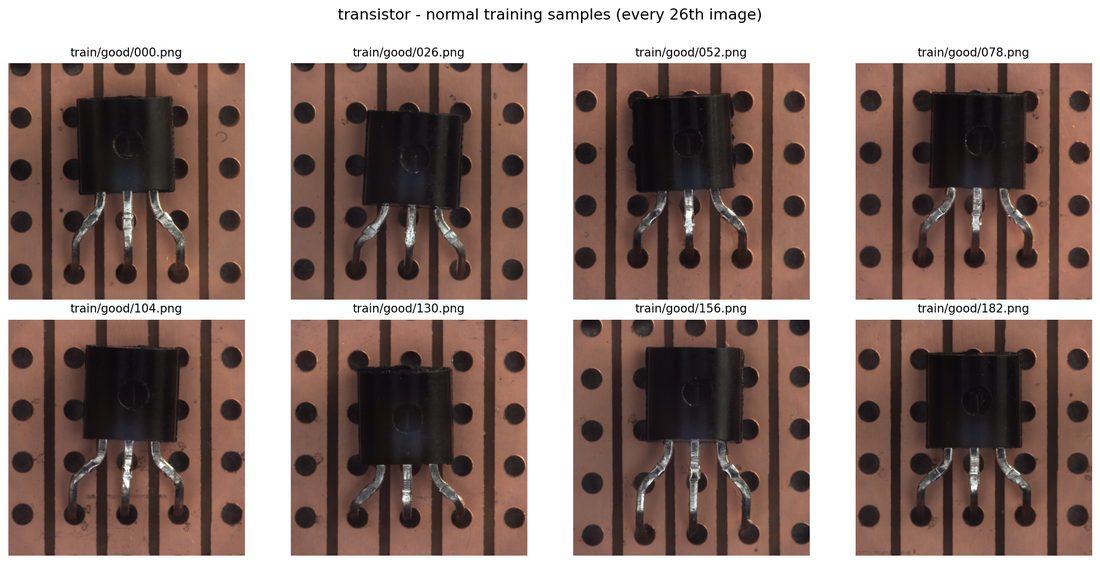

anomalous_test_samples.png


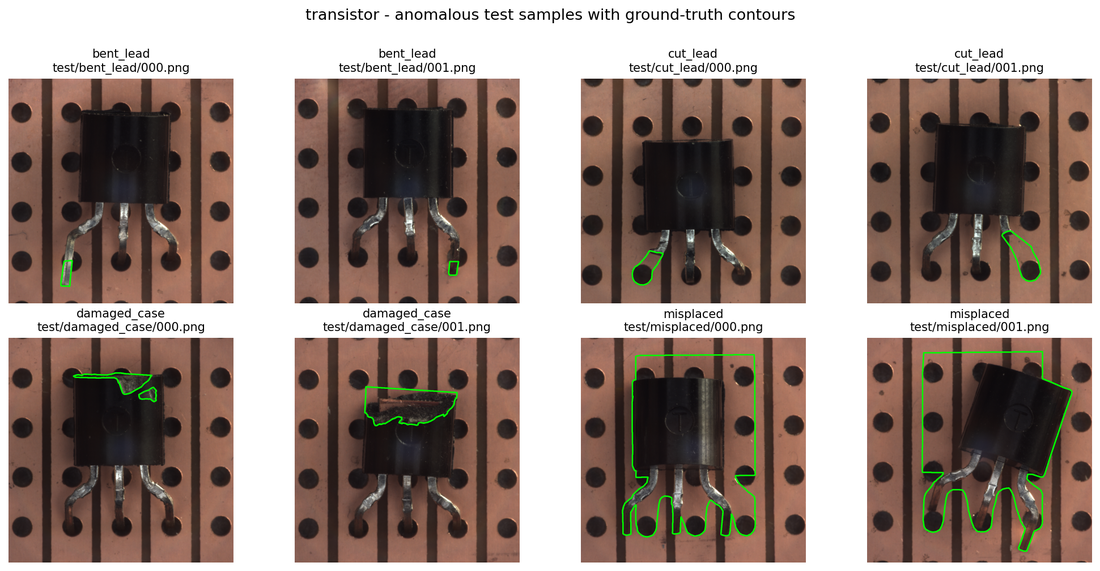

In [7]:
for name in ("normal_training_samples.png", "anomalous_test_samples.png"):
    print(name)
    show(PROJECT_ROOT / eda["figures"][name], width=1100)

## Defect area and appearance

defect_area_distribution.png


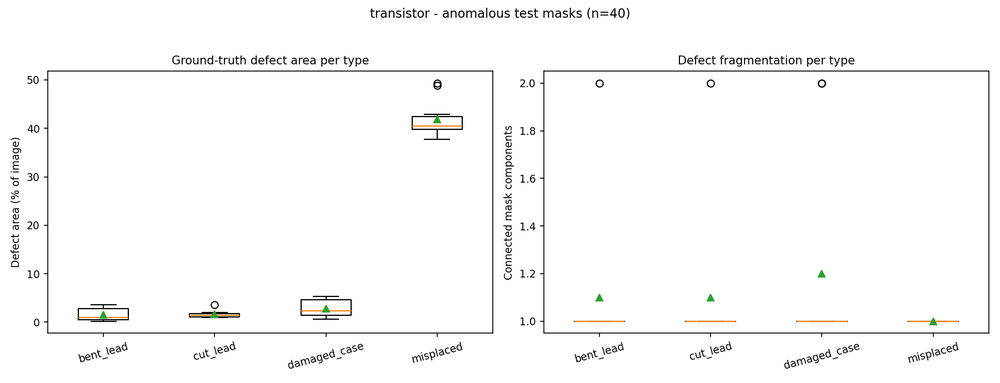

appearance_scatter.png


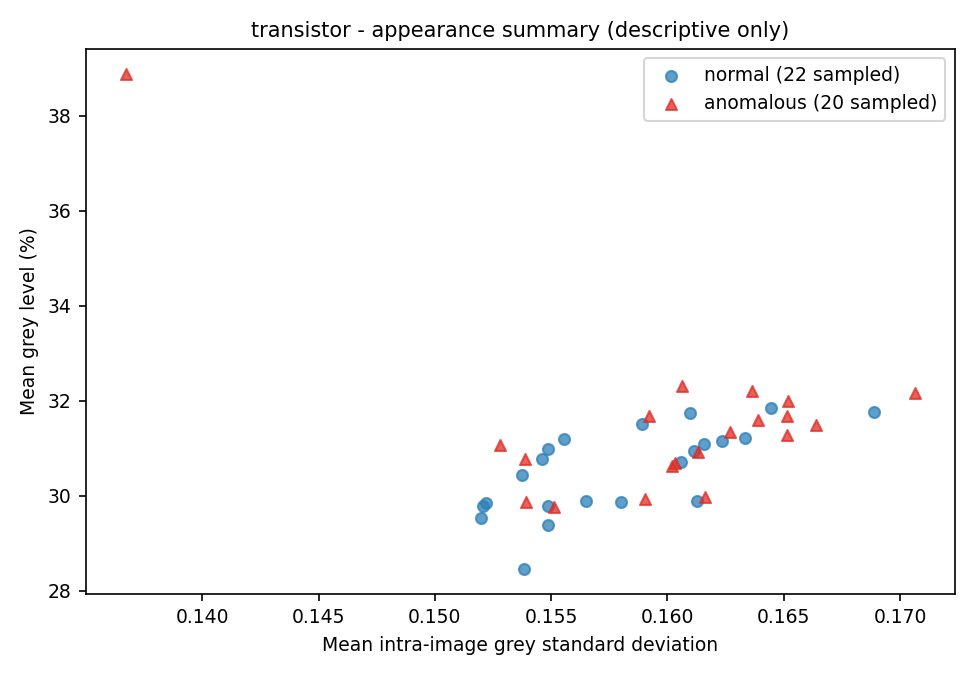

In [8]:
for name in ("defect_area_distribution.png", "appearance_scatter.png"):
    print(name)
    show(PROJECT_ROOT / eda["figures"][name], width=1000)

## What this implies for the modelling

- **Category scope.** The project scope is final and frozen at exactly six MVTec AD
  categories: `transistor`, `cable`, `leather`, `bottle`, `capsule`, `grid`. The other nine
  categories (`carpet`, `hazelnut`, `metal_nut`, `pill`, `screw`, `tile`, `toothbrush`,
  `wood`, `zipper`) are intentionally out of scope: they are not downloaded, trained,
  evaluated or served, and the CLI/app rejects them before loading any artifact. This
  notebook therefore describes `transistor` only, and no cross-category claim is made here.
- **Normal-only training.** All 213 training images are defect-free. The 170 fit / 43
  calibration split is deterministic (`seed=42`) and recorded in
  `data/processed/splits/transistor.json`.
- **Two difficulty regimes.** `misplaced` components cover about 40% of the image, while
  lead and case defects cover roughly 0.2-5%. A detector can rank whole images well and
  still localise small defects poorly, so image-level and pixel-level metrics are reported
  separately. Pooled pixel metrics are dominated by the large `misplaced` regions.
- **Descriptive test use.** The test split appears here only to characterise the evaluation
  data. No test annotation is used for training, threshold calibration or model selection.